<a href="https://colab.research.google.com/github/paolorch/CEIA-Vision-Computadora-I-TP1/blob/main/TP1_VC1_ROJAS_CHACON.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Universidad de Buenos Aires - FIUBA - LSE**
### **Visión por computadora I - TP1**

5to bimestre 2026

### Docente: **Maxim Dorogov**

### Alumno: **André Paolo Rojas Chacón**
Nro. SIU: **a2713**

### Introducción

Este trabajo práctico comprende dos actividades de procesamiento de imágenes. La primera consiste en implementar el algoritmo White Patch para corregir diferencias de color producidas por la iluminación y evaluar sus limitaciones. La segunda aborda el análisis de histogramas en imágenes en escala de grises, comparando sus distribuciones de intensidad y su posible utilidad como características para tareas de visión por computadora.

### Consignas del trabajo práctico

**Parte 1 – White Patch**

1. Implementar el algoritmo White Patch para eliminar las diferencias de color debidas a la iluminación en las imágenes de `/white_patch`.
2. Mostrar los resultados obtenidos y analizar las posibles fallas del algoritmo.

**Parte 2 – Histogramas**

1. Leer `img1_tp.png` y `img2_tp.png` con OpenCV en escala de grises y visualizarlas.
2. Elegir un número adecuado de bins, graficar y comparar sus histogramas. Explicar las observaciones y analizar si estos pueden utilizarse como características para un modelo de clasificación o detección de imágenes.


## 1. Corrección de iluminación con White Patch

### 1.1 Carga de imágenes

Se cargan las imágenes de la carpeta `white_patch` y se revisan sus dimensiones y apariencia original para establecer una referencia antes de aplicar el algoritmo.

test_blue.png: 278 x 100 píxeles
test_green.png: 278 x 100 píxeles
test_red.png: 276 x 99 píxeles
wp_blue.jpg: 1200 x 1600 píxeles
wp_green.png: 363 x 571 píxeles
wp_green2.jpg: 1200 x 1600 píxeles
wp_red.png: 481 x 813 píxeles
wp_red2.jpg: 1200 x 1600 píxeles

Total de imágenes: 8


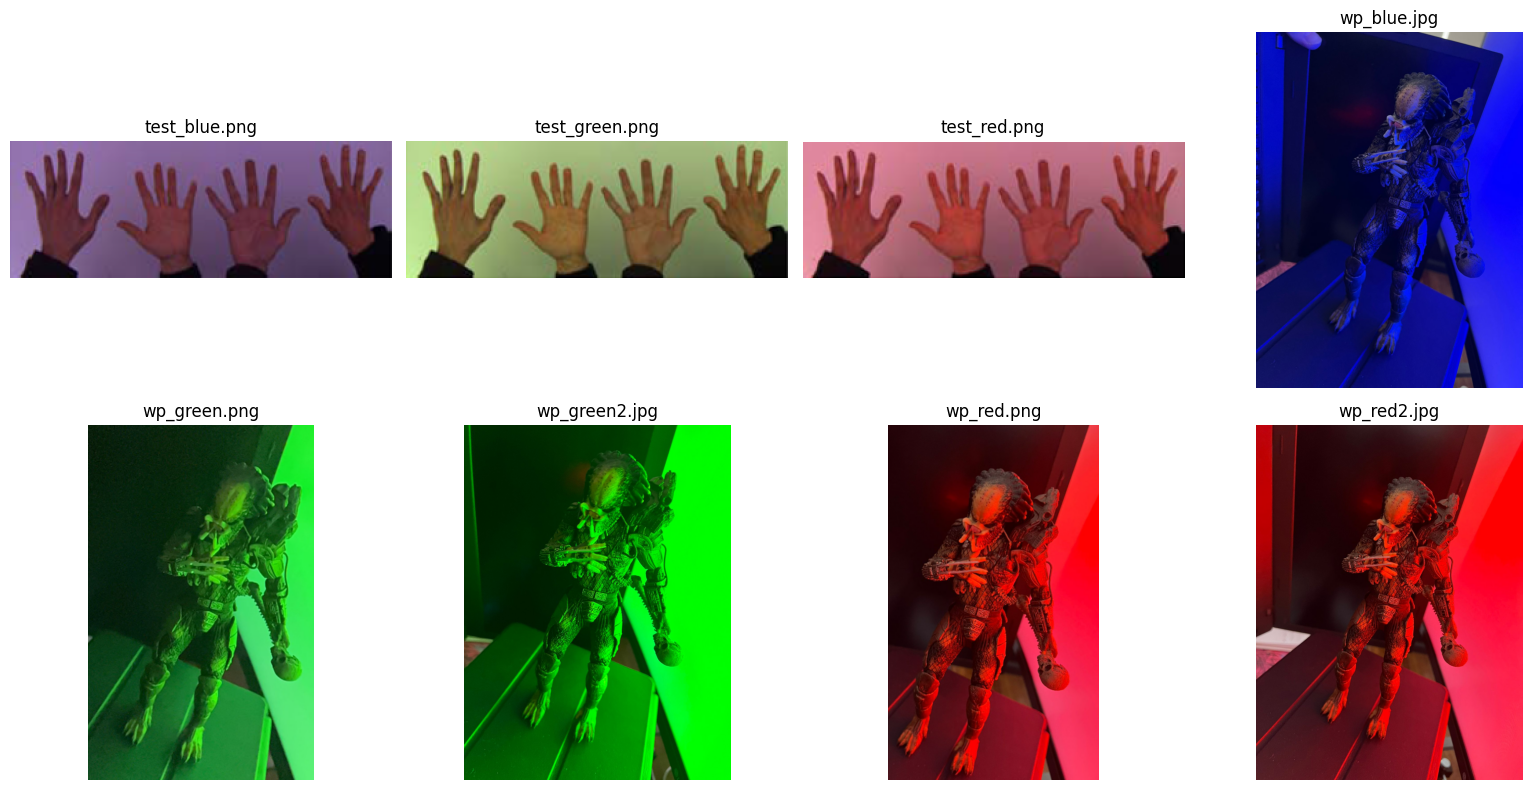

In [3]:

import cv2 as cv
import matplotlib.pyplot as plt

# Imágenes proporcionadas para White Patch
ruta = '/content/TP1/white_patch'

archivos = [
    'test_blue.png', 'test_green.png', 'test_red.png',
    'wp_blue.jpg', 'wp_green.png', 'wp_green2.jpg',
    'wp_red.png', 'wp_red2.jpg'
]

imagenes = {}

# Lectura y verificación
for nombre in archivos:
    imagen = cv.imread(f'{ruta}/{nombre}')

    if imagen is None:
        raise ValueError(f'No se pudo leer: {nombre}')

    imagenes[nombre] = imagen
    alto, ancho = imagen.shape[:2]
    print(f'{nombre}: {ancho} x {alto} píxeles')

print(f'\nTotal de imágenes: {len(imagenes)}')

# Visualización de imágenes originales
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (nombre, imagen) in zip(axes.flat, imagenes.items()):
    ax.imshow(cv.cvtColor(imagen, cv.COLOR_BGR2RGB))
    ax.set_title(nombre)
    ax.axis('off')

plt.tight_layout()
plt.show()



**Observaciones**

Se cargaron correctamente las ocho imágenes. Las tres imágenes de prueba muestran una misma escena con dominantes azules, verdes y rojas. Las cinco fotografías restantes presentan una figura bajo distintas condiciones de iluminación, también con marcadas dominantes de color.

Este conjunto permitirá evaluar la corrección tanto en imágenes de prueba como en fotografías con iluminación de distintos colores.


### 1.2 Análisis previo de los canales

Antes de aplicar White Patch, se obtienen los valores máximos de los canales B, G y R en cada imagen. Esto permite revisar las condiciones iniciales de cada caso y anticipar posibles limitaciones del algoritmo, especialmente cuando alguno de los canales ya presenta valores saturados.

In [4]:
# Máximos por canal en las imágenes originales
maximos_originales = {}

print(f'{"Imagen":<20} {"B":>5} {"G":>5} {"R":>5}')
print('-' * 38)

for nombre, imagen in imagenes.items():
    max_b = int(imagen[:, :, 0].max())
    max_g = int(imagen[:, :, 1].max())
    max_r = int(imagen[:, :, 2].max())

    maximos_originales[nombre] = (max_b, max_g, max_r)

    print(f'{nombre:<20} {max_b:>5} {max_g:>5} {max_r:>5}')

Imagen                   B     G     R
--------------------------------------
test_blue.png          200   138   165
test_green.png         171   250   210
test_red.png           175   157   247
wp_blue.jpg            255   255   255
wp_green.png           155   252   126
wp_green2.jpg          172   255   170
wp_red.png             122   134   255
wp_red2.jpg            203   201   255



**Observaciones**

Las tres imágenes de prueba y `wp_green.png` presentan máximos inferiores a 255 en todos sus canales.

En cambio, `wp_blue.jpg` alcanza 255 en los tres canales, por lo que la corrección basada en máximos no producirá cambios. En `wp_green2.jpg`, `wp_red.png` y `wp_red2.jpg`, al menos un canal alcanza ese valor, lo que limita su ajuste individual.

Estos resultados permiten identificar posibles limitaciones del método, que se evaluarán al aplicar White Patch.


### 1.3 Aplicación de White Patch

Se aplica White Patch a las ocho imágenes utilizando los máximos absolutos de cada canal. Se presentan los factores de corrección y se comparan las imágenes originales con las procesadas para evaluar los resultados del algoritmo.

Imagen                      B        G        R
-----------------------------------------------
test_blue.png           1.275    1.848    1.545
test_green.png          1.491    1.020    1.214
test_red.png            1.457    1.624    1.032
wp_blue.jpg             1.000    1.000    1.000
wp_green.png            1.645    1.012    2.024
wp_green2.jpg           1.483    1.000    1.500
wp_red.png              2.090    1.903    1.000
wp_red2.jpg             1.256    1.269    1.000


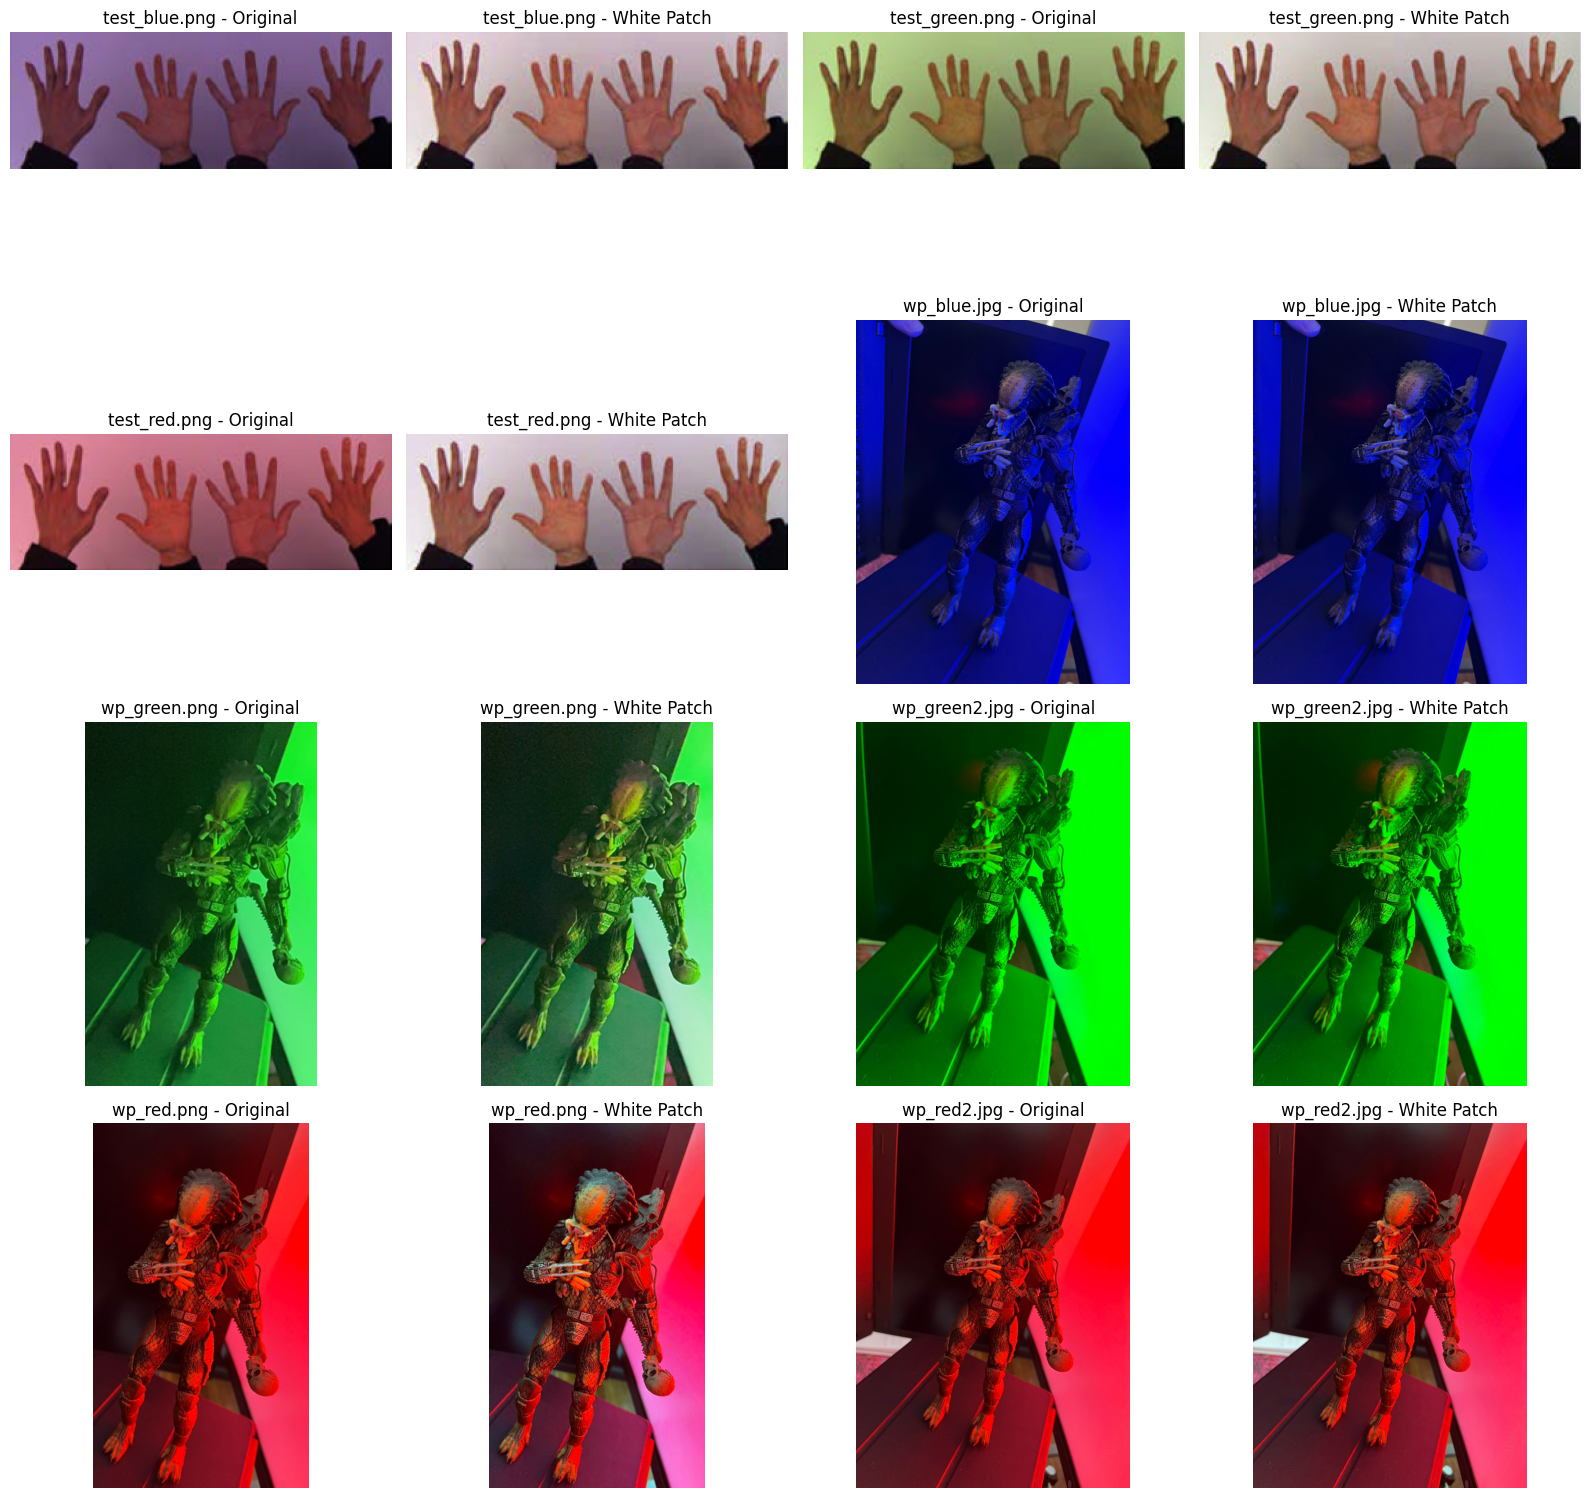

In [5]:

import numpy as np

# Implementación del algoritmo White Patch
def white_patch(imagen):
    img_float = imagen.astype('float32')

    # Máximos por canal (B, G, R)
    maximos = np.max(img_float, axis=(0, 1))

    # Factores de corrección
    factores = np.ones(3, dtype='float32')

    for i in range(3):
        if maximos[i] > 0:
            factores[i] = 255.0 / maximos[i]

    # Corrección y conversión a 8 bits
    img_corregida = img_float * factores
    np.clip(img_corregida, 0, 255, out=img_corregida)

    return img_corregida.astype('uint8'), factores


# Aplicación a todas las imágenes
resultados = {}

print(f'{"Imagen":<20} {"B":>8} {"G":>8} {"R":>8}')
print('-' * 47)

for nombre, imagen in imagenes.items():
    corregida, factores = white_patch(imagen)
    resultados[nombre] = corregida

    print(f'{nombre:<20} {factores[0]:>8.3f} '
          f'{factores[1]:>8.3f} {factores[2]:>8.3f}')


# Comparación entre imágenes originales y corregidas
fig, axes = plt.subplots(4, 4, figsize=(16, 16))

for i, (nombre, imagen) in enumerate(imagenes.items()):
    ax_original = axes.flat[2 * i]
    ax_corregida = axes.flat[2 * i + 1]

    ax_original.imshow(cv.cvtColor(imagen, cv.COLOR_BGR2RGB))
    ax_original.set_title(f'{nombre} - Original')
    ax_original.axis('off')

    ax_corregida.imshow(cv.cvtColor(resultados[nombre], cv.COLOR_BGR2RGB))
    ax_corregida.set_title(f'{nombre} - White Patch')
    ax_corregida.axis('off')

plt.tight_layout()
plt.show()



**Observaciones**

- En las tres imágenes de prueba (`test_blue`, `test_green` y `test_red`), White Patch reduce notablemente las dominantes de color. Los fondos recuperan tonalidades más neutras y los colores de las manos resultan más naturales.

- Los factores de corrección muestran que los mayores ajustes se aplican a los canales con menor intensidad máxima. Por ejemplo, en `test_blue.png`, el canal verde recibe el mayor factor (1.848), mientras que en `test_red.png` los ajustes más importantes corresponden al verde (1.624) y al azul (1.457).

- Como se anticipó en el análisis previo, `wp_blue.jpg` permanece sin cambios. Sus tres canales alcanzan el valor 255, por lo que todos los factores son iguales a 1.

- En `wp_green.png` se observa una recuperación parcial de los colores de la figura y del fondo. El canal rojo recibe el mayor ajuste (2.024), aunque la dominante verde sigue siendo visible. En `wp_green2.jpg`, la corrección también es limitada, especialmente en las zonas iluminadas de verde.

- En `wp_red.png`, los factores del azul (2.090) y del verde (1.903) permiten recuperar detalles y tonalidades que antes quedaban dominados por el rojo. Sin embargo, aparecen zonas azuladas y magentas, mientras que la iluminación roja continúa siendo predominante.

- En `wp_red2.jpg`, los cambios son menos notorios. Los factores del azul (1.256) y del verde (1.269) producen un ajuste moderado, insuficiente para eliminar visualmente la dominante roja.

En conjunto, White Patch ofrece resultados más favorables en las imágenes de prueba que en las fotografías con iluminación intensa. La corrección mediante máximos absolutos presenta limitaciones que requieren un análisis más detallado.



### 1.4 Análisis de resultados

Se comparan los histogramas RGB de las ocho imágenes antes y después de aplicar White Patch. También se calcula el porcentaje de píxeles con intensidad 255 en cada canal de las imágenes originales.

Este análisis permitirá relacionar los cambios observados con la distribución de intensidades y evaluar las limitaciones de la corrección basada en máximos absolutos.


Píxeles con intensidad 255 en imágenes originales (%)

Imagen                        B          G          R
----------------------------------------------------
test_blue.png            0.0000     0.0000     0.0000
test_green.png           0.0000     0.0000     0.0000
test_red.png             0.0000     0.0000     0.0000
wp_blue.jpg              0.5072     0.0028     0.0011
wp_green.png             0.0000     0.0000     0.0000
wp_green2.jpg            0.0000     5.1398     0.0000
wp_red.png               0.0000     0.0000     6.4602
wp_red2.jpg              0.0000     0.0000     9.1039


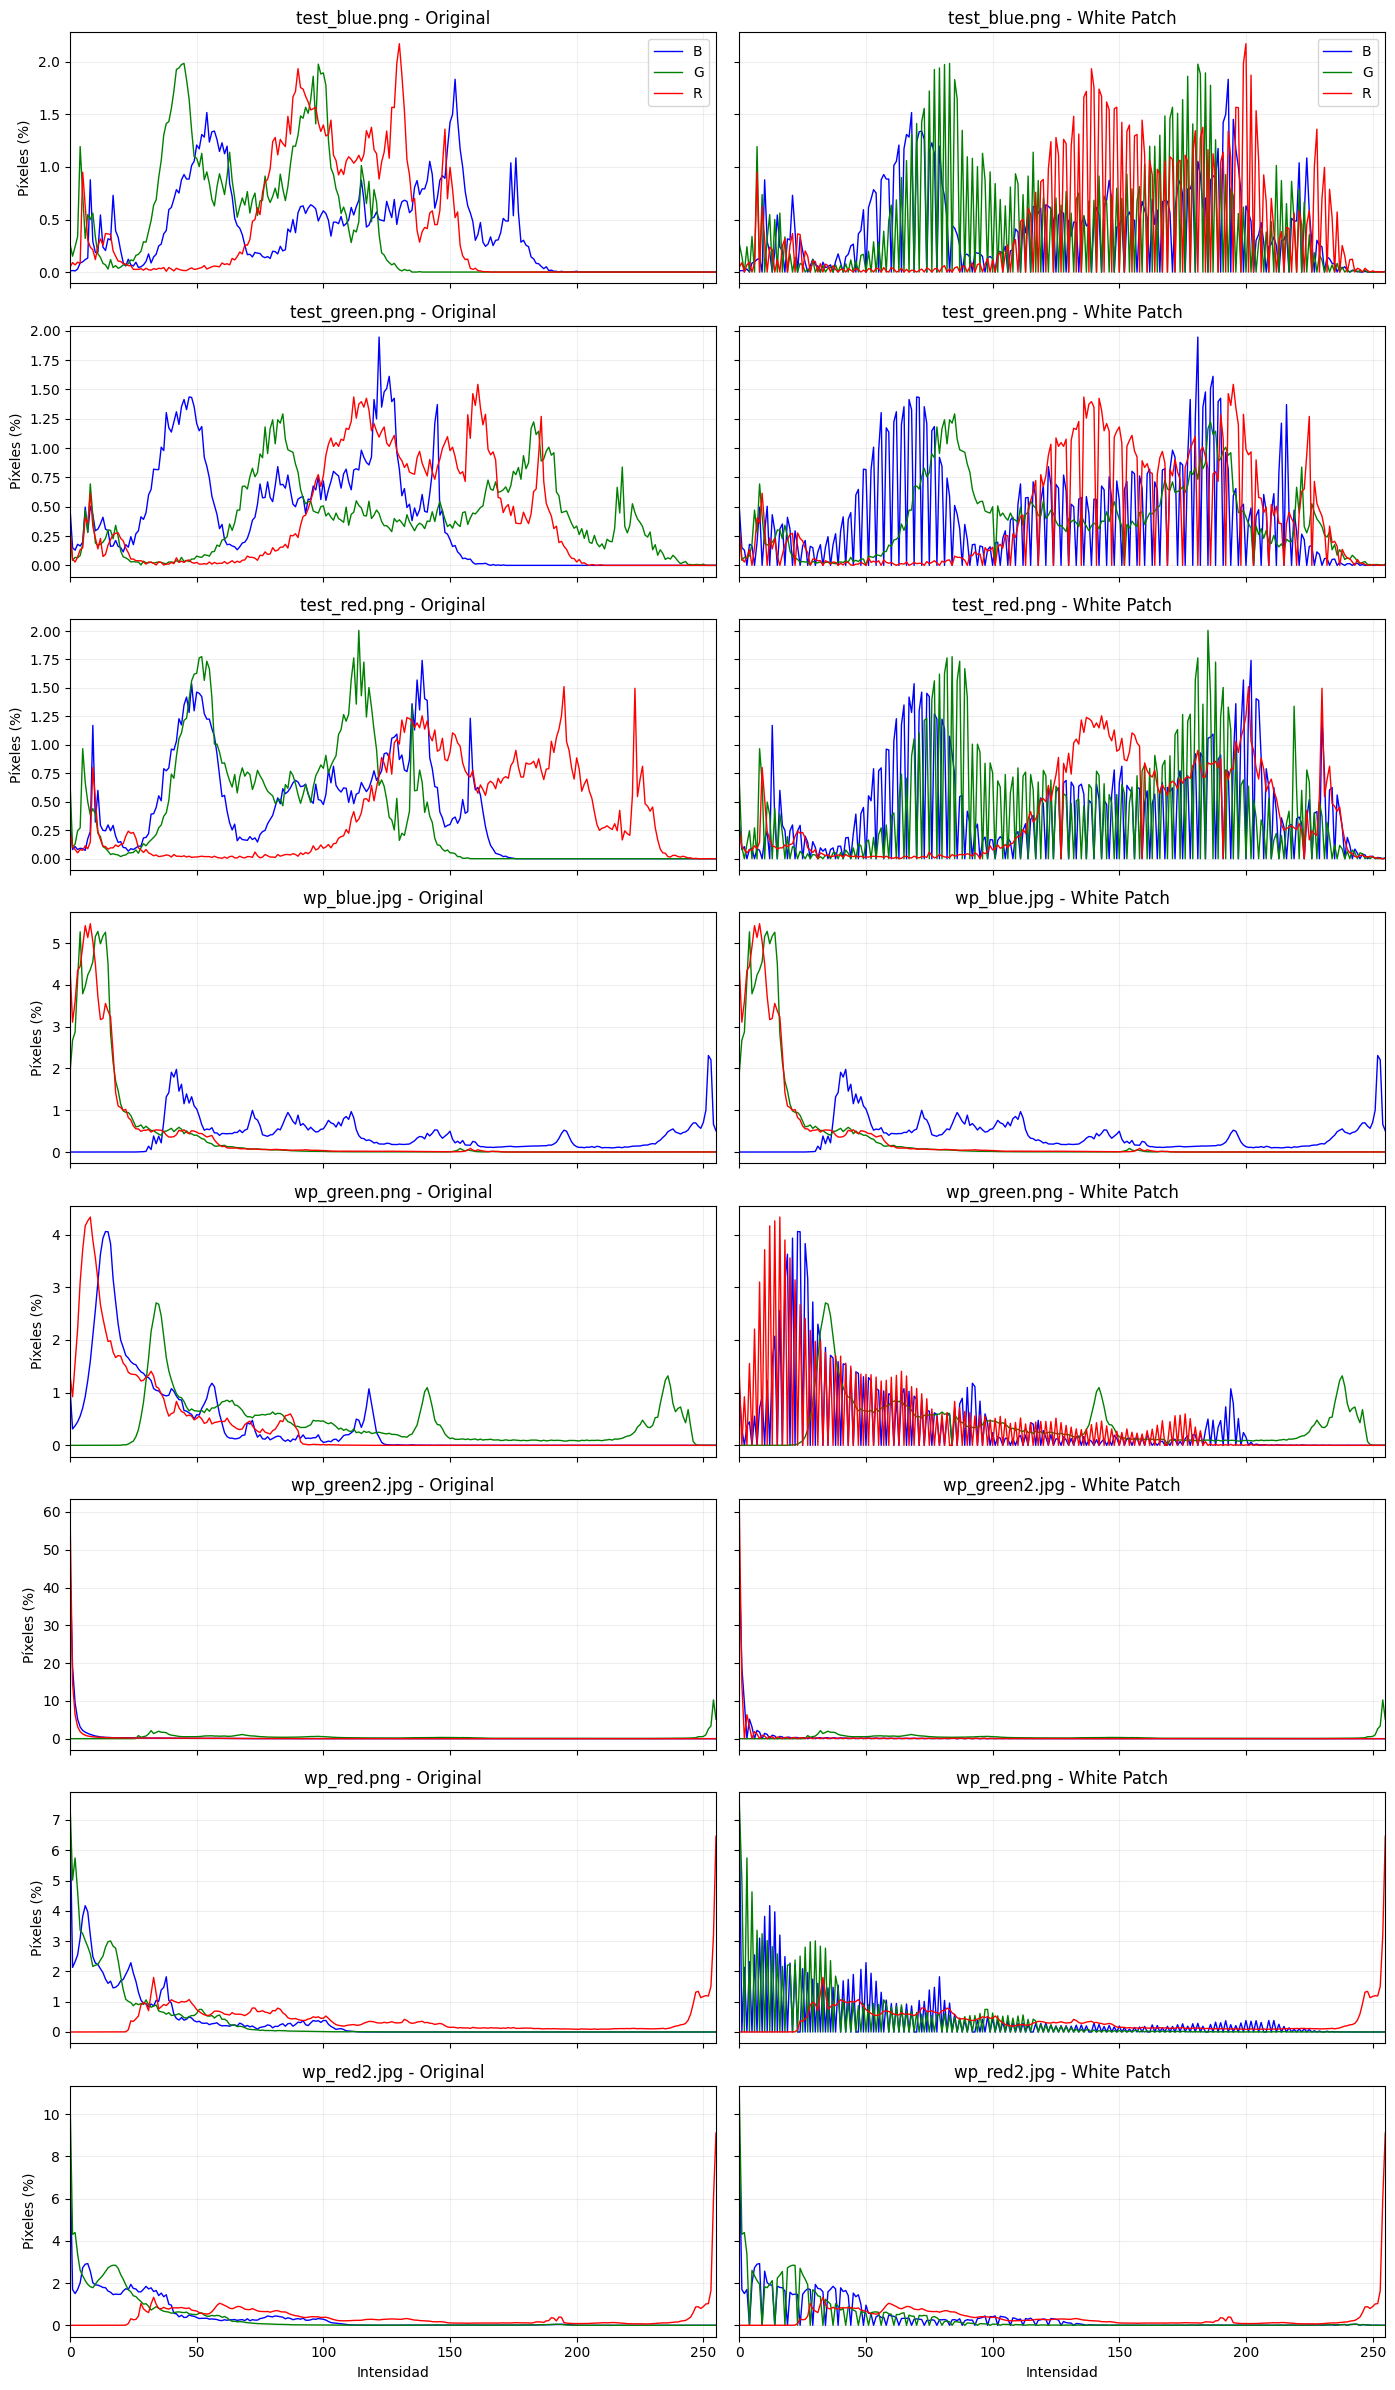

In [6]:

# Porcentaje de píxeles con intensidad 255 por canal
print('Píxeles con intensidad 255 en imágenes originales (%)\n')
print(f'{"Imagen":<20} {"B":>10} {"G":>10} {"R":>10}')
print('-' * 52)

for nombre, imagen in imagenes.items():
    saturacion = np.mean(imagen == 255, axis=(0, 1)) * 100

    print(f'{nombre:<20} {saturacion[0]:>10.4f} '
          f'{saturacion[1]:>10.4f} {saturacion[2]:>10.4f}')


# Histogramas RGB de las ocho imágenes
casos = list(imagenes.keys())

colores = ['blue', 'green', 'red']
canales = ['B', 'G', 'R']

fig, axes = plt.subplots(8, 2, figsize=(14, 24),
                         sharex=True, sharey='row')

for i, nombre in enumerate(casos):
    versiones = [imagenes[nombre], resultados[nombre]]

    for j, imagen in enumerate(versiones):
        ax = axes[i, j]

        # Histograma de cada canal
        for canal in range(3):
            hist, _ = np.histogram(
                imagen[:, :, canal].ravel(), 256, [0, 256]
            )

            # Frecuencia relativa para comparar imágenes
            frecuencia = hist * 100 / imagen[:, :, canal].size

            ax.plot(frecuencia, color=colores[canal],
                    label=canales[canal], linewidth=1)

        version = 'Original' if j == 0 else 'White Patch'
        ax.set_title(f'{nombre} - {version}')
        ax.set_xlim(0, 255)
        ax.grid(alpha=0.2)

        if j == 0:
            ax.set_ylabel('Píxeles (%)')

        if i == 0:
            ax.legend()

        if i == len(casos) - 1:
            ax.set_xlabel('Intensidad')

plt.tight_layout()
plt.show()



**Observaciones**

- Las tres imágenes de prueba no presentan píxeles con intensidad 255. Tras aplicar White Patch, sus histogramas muestran una redistribución de las intensidades hacia valores más altos, especialmente en los canales que recibieron mayores factores de corrección. Esto coincide con la reducción de las dominantes de color observada anteriormente.

- En `wp_blue.jpg`, los tres histogramas permanecen idénticos. Aunque solamente el 0.5072 % de los píxeles azules, el 0.0028 % de los verdes y el 0.0011 % de los rojos alcanzan 255, estos valores bastan para que los factores sean iguales a 1. Esto evidencia la sensibilidad del método a los máximos absolutos, incluso cuando corresponden a muy pocos píxeles.

- `wp_green.png` no presenta píxeles en 255, pero conserva parte de su dominante verde después de la corrección. Los histogramas muestran una ampliación de las intensidades de los canales azul y rojo, mientras que el verde cambia muy poco. Por tanto, la ausencia de saturación no garantiza una corrección completa del color.

- En `wp_green2.jpg`, el 5.1398 % de los píxeles del canal verde alcanza 255. Este canal permanece sin ajuste y conserva su acumulación en el extremo superior del histograma. Aunque los canales azul y rojo se amplían, sus distribuciones siguen concentradas principalmente en intensidades bajas, lo que ayuda a explicar la persistencia del verde.

- En `wp_red.png` y `wp_red2.jpg`, el canal rojo presenta un 6.4602 % y un 9.1039 % de píxeles en 255, respectivamente. Los picos en ese extremo permanecen después del procesamiento. En `wp_red.png`, los mayores ajustes de los canales azul y verde producen cambios más notorios, mientras que en `wp_red2.jpg` la redistribución es menor y la dominante roja continúa siendo evidente.

- Los histogramas corregidos presentan picos más estrechos y espacios entre niveles de intensidad, especialmente en las imágenes de prueba. Esto se debe al escalado de los valores discretos y su posterior conversión a `uint8`. La operación redistribuye las intensidades, pero no recupera información que ya se haya perdido por saturación.

- También se observan concentraciones importantes de píxeles en intensidades cercanas a cero en varias fotografías reales. Aunque White Patch amplía algunos canales, estas regiones permanecen mayormente oscuras, lo que limita la recuperación visual de sus colores.

Los resultados muestran que los máximos absolutos pueden condicionar considerablemente la corrección. Esto justifica evaluar el uso de percentiles, especialmente en las imágenes con píxeles en 255, sin asumir que dicha alternativa resolverá por completo las dominantes de color.



### 1.5 Corrección mediante percentiles

Se evalúa una variante de White Patch que utiliza percentiles en lugar de máximos absolutos. Se comparan los percentiles 99 y 90 para analizar su comportamiento en las imágenes con distintos niveles de saturación.

Los resultados se contrastan con la implementación original para identificar las mejoras obtenidas y los posibles efectos de una corrección más intensa.


Factores de corrección por percentil

Imagen                  P99 B    P99 G    P99 R    P90 B    P90 G    P90 R
--------------------------------------------------------------------------
test_blue.png           1.417    2.090    1.667    1.604    2.383    1.821
test_green.png          1.700    1.109    1.321    1.903    1.269    1.449
test_red.png            1.564    1.783    1.109    1.759    2.056    1.220
wp_blue.jpg             1.004    2.965    2.179    1.041    6.220    5.795
wp_green.png            2.125    1.045    2.898    3.188    1.094    3.984
wp_green2.jpg           4.554    1.000    3.643   28.333    1.004   28.333
wp_red.png              2.500    3.446    1.000    3.923    5.204    1.008
wp_red2.jpg             2.143    2.143    1.000    3.312    5.204    1.004


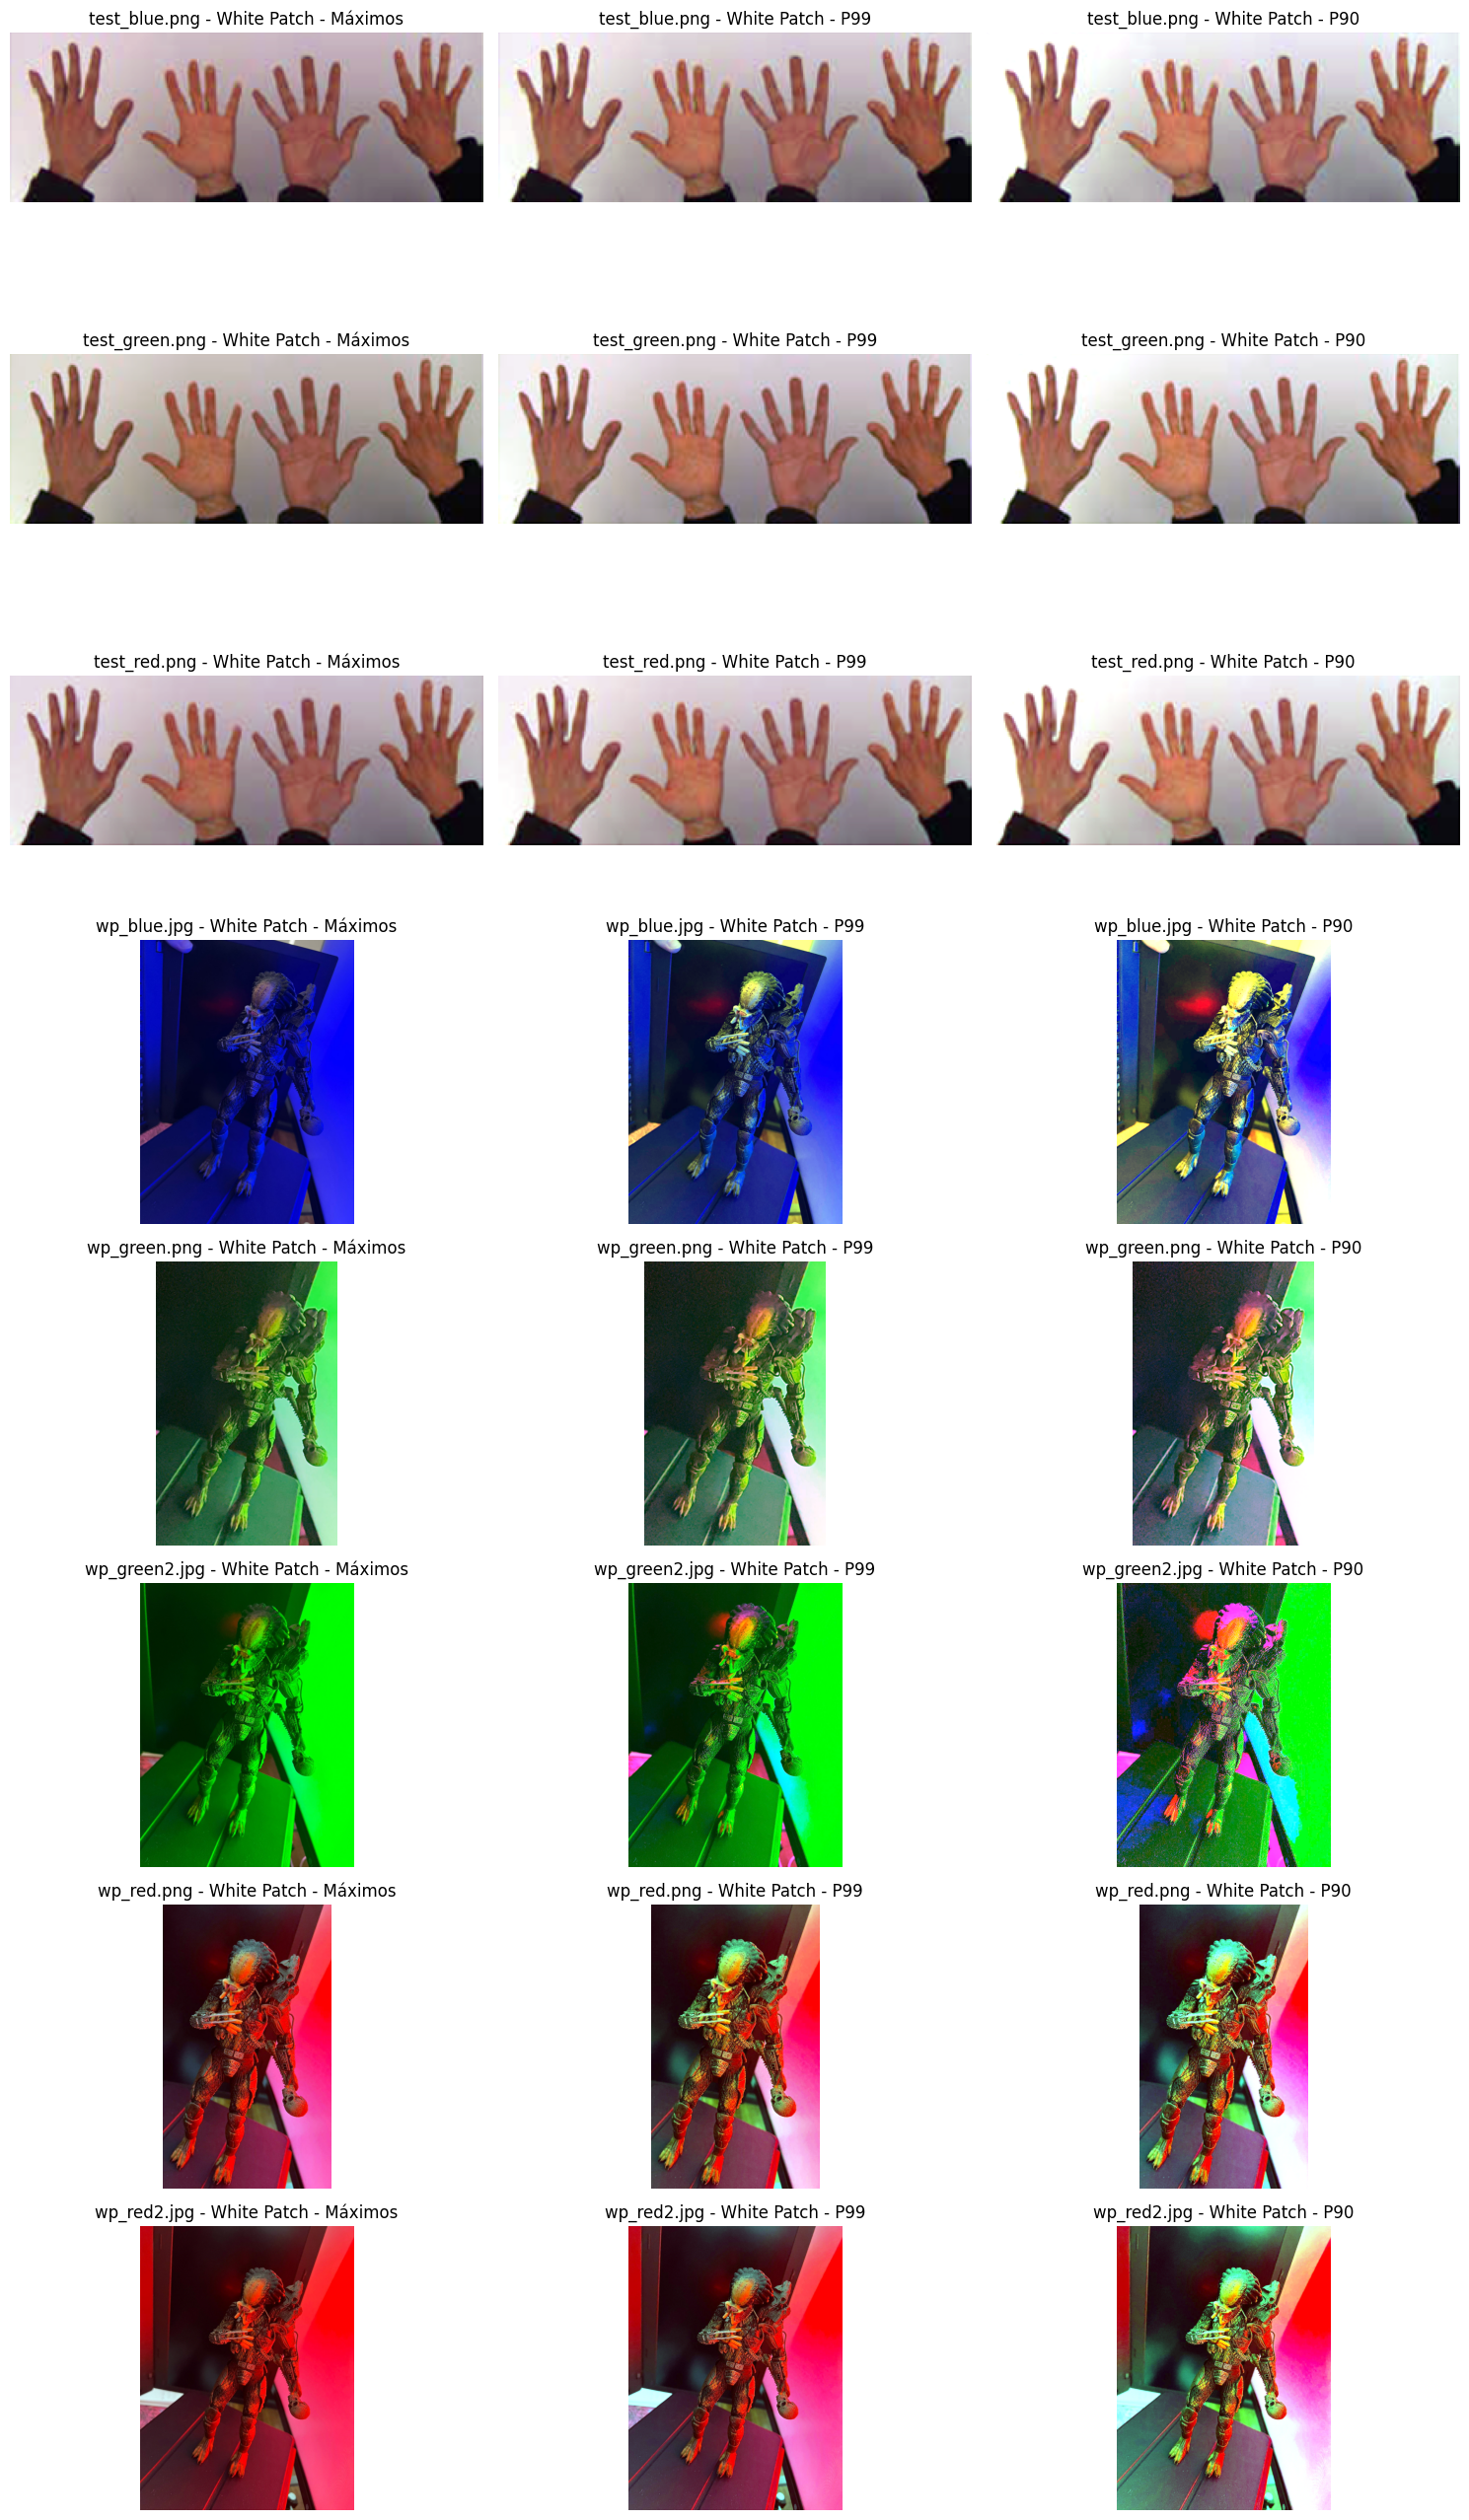

In [7]:

# Implementación de White Patch mediante percentiles
def white_patch_percentil(imagen, percentil):
    img_float = imagen.astype('float32')

    # Percentil por canal (B, G, R)
    valores = np.percentile(img_float, percentil, axis=(0, 1))

    # Factores de corrección
    factores = np.ones(3, dtype='float32')

    for i in range(3):
        if valores[i] > 0:
            factores[i] = 255.0 / valores[i]

    # Corrección y conversión a 8 bits
    img_corregida = img_float * factores
    np.clip(img_corregida, 0, 255, out=img_corregida)

    return img_corregida.astype('uint8'), factores


# Aplicación de los percentiles 99 y 90
resultados_p99 = {}
resultados_p90 = {}

print('Factores de corrección por percentil\n')
print(f'{"Imagen":<20} {"P99 B":>8} {"P99 G":>8} {"P99 R":>8} '
      f'{"P90 B":>8} {"P90 G":>8} {"P90 R":>8}')
print('-' * 74)

for nombre, imagen in imagenes.items():
    corregida_99, factores_99 = white_patch_percentil(imagen, 99)
    corregida_90, factores_90 = white_patch_percentil(imagen, 90)

    resultados_p99[nombre] = corregida_99
    resultados_p90[nombre] = corregida_90

    print(f'{nombre:<20} '
          f'{factores_99[0]:>8.3f} {factores_99[1]:>8.3f} {factores_99[2]:>8.3f} '
          f'{factores_90[0]:>8.3f} {factores_90[1]:>8.3f} {factores_90[2]:>8.3f}')


# Comparación de los tres métodos
fig, axes = plt.subplots(8, 3, figsize=(15, 26))

for i, nombre in enumerate(imagenes):
    versiones = [
        resultados[nombre],
        resultados_p99[nombre],
        resultados_p90[nombre]
    ]

    titulos = ['White Patch - Máximos',
               'White Patch - P99',
               'White Patch - P90']

    for j, imagen in enumerate(versiones):
        axes[i, j].imshow(cv.cvtColor(imagen, cv.COLOR_BGR2RGB))
        axes[i, j].set_title(f'{nombre} - {titulos[j]}')
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()



**Observaciones**

- En las tres imágenes de prueba, el percentil 99 produce resultados similares a White Patch con máximos, aunque ligeramente más luminosos. Con el percentil 90, los fondos se aclaran aún más, pero algunas zonas pierden contraste. En estos casos, la corrección original ya ofrecía buenos resultados.

- En `wp_blue.jpg`, el uso de percentiles permite corregir una imagen que permanecía completamente inalterada con máximos absolutos. Con P99, los factores del verde (2.965) y del rojo (2.179) permiten recuperar parte de los colores de la figura, aunque persiste la iluminación azul. Con P90, estos factores aumentan a 6.220 y 5.795, generando zonas excesivamente iluminadas y tonalidades amarillentas.

- En `wp_green.png`, P99 mejora parcialmente la apariencia de la figura y del fondo. Con P90, los factores del azul (3.188) y del rojo (3.984) producen cambios más intensos, pero también aparecen tonalidades magentas y una mayor saturación en algunas regiones.

- `wp_green2.jpg` presenta el caso más extremo. Con P99, el canal verde permanece sin ajuste, mientras que el azul y el rojo aumentan considerablemente. Al utilizar P90, ambos alcanzan factores de 28.333, provocando una alteración excesiva de los colores. La figura presenta zonas cian y magentas muy intensas, sin eliminar la dominante verde del fondo.

- En `wp_red.png` y `wp_red2.jpg`, el percentil 99 mantiene el factor del canal rojo en 1 debido a la cantidad de píxeles saturados. Con P90, este factor apenas supera la unidad (1.008 y 1.004), mientras que los canales azul y verde reciben ajustes mucho mayores. Esto reduce parcialmente la apariencia rojiza de la figura, pero introduce tonalidades verdosas y cian, especialmente en `wp_red2.jpg`.

- La comparación evidencia que los percentiles ayudan a superar la dependencia de los máximos absolutos, pero su elección resulta importante. Un percentil demasiado bajo puede producir factores elevados, llevando numerosos valores al límite de 255 y perdiendo diferencias de intensidad en las zonas afectadas.

- En las fotografías con iluminación intensa, ningún método recupera completamente los colores naturales de la escena. Los percentiles permiten mejorar algunos resultados, pero no pueden recuperar la información perdida por saturación ni compensar todas las alteraciones producidas por la iluminación.

En conjunto, P99 ofrece una corrección más moderada, mientras que P90 resulta demasiado agresivo en varios casos. Los resultados muestran que no existe un percentil que ofrezca la mejor corrección para todas las imágenes, por lo que es necesario evaluar cada resultado y evitar ajustes que introduzcan nuevas distorsiones.



### Conclusiones de la Parte 1

- White Patch logró reducir las dominantes de color en las imágenes de prueba, mientras que en las fotografías con iluminación intensa los resultados fueron parciales.

- El análisis de los canales y sus histogramas permitió comprobar que incluso una pequeña cantidad de píxeles en 255 puede impedir la corrección basada en máximos absolutos.

- El uso de percentiles permitió mejorar algunos resultados, especialmente en `wp_blue.jpg`. Sin embargo, P90 produjo ajustes excesivos en varias fotografías, mientras que P99 mostró un comportamiento más moderado.

- La corrección más intensa no siempre fue la mejor. Los resultados evidencian la importancia de considerar la saturación y evaluar los cambios visuales, ya que el algoritmo no puede recuperar información perdida.

En general, White Patch resultó útil para compensar diferencias de iluminación, aunque su efectividad dependió de las características de cada imagen y del valor de referencia utilizado.



## 2. Análisis de histogramas

### 2.1 Carga y visualización de imágenes

Se cargan `img1_tp.png` y `img2_tp.png` en escala de grises mediante OpenCV. Se verifican sus dimensiones y se visualizan ambas imágenes para realizar una primera comparación.


img1_tp.png: 287 x 288 píxeles
img2_tp.png: 287 x 288 píxeles


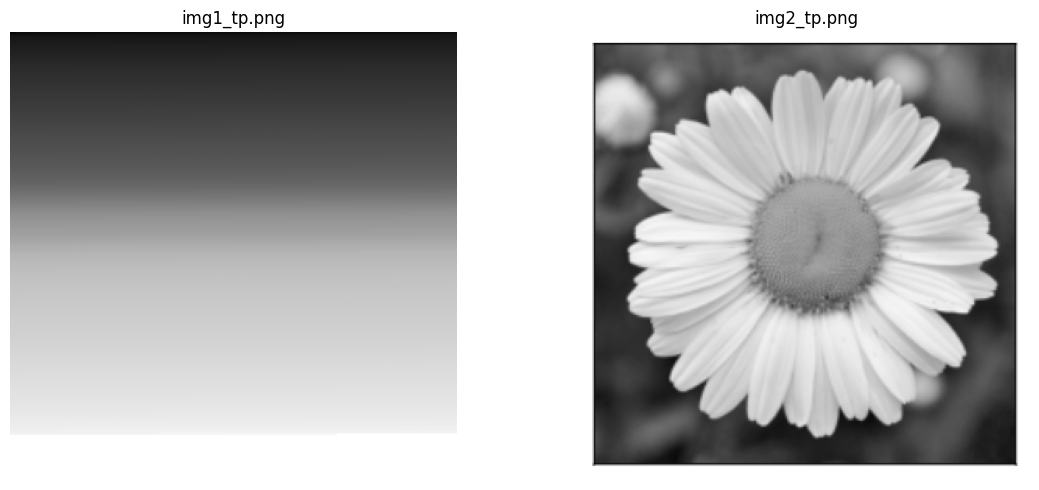

In [8]:

# Lectura de imágenes en escala de grises
ruta = '/content/TP1'

nombres = ['img1_tp.png', 'img2_tp.png']
imagenes_grises = {}

for nombre in nombres:
    imagen = cv.imread(f'{ruta}/{nombre}', cv.IMREAD_GRAYSCALE)

    if imagen is None:
        raise ValueError(f'No se pudo leer: {nombre}')

    imagenes_grises[nombre] = imagen

    alto, ancho = imagen.shape
    print(f'{nombre}: {ancho} x {alto} píxeles')


# Visualización de las imágenes originales
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (nombre, imagen) in zip(axes, imagenes_grises.items()):
    ax.imshow(imagen, cmap='gray', vmin=0, vmax=255)
    ax.set_title(nombre)
    ax.axis('off')

plt.tight_layout()
plt.show()



**Observaciones**

- Ambas imágenes tienen una resolución de 287 × 288 píxeles y se visualizaron correctamente en escala de grises.

- `img1_tp.png` presenta un gradiente vertical de intensidad, desde tonos oscuros en la parte superior hasta tonos claros en la inferior, sin cambios bruscos entre regiones.

- `img2_tp.png` muestra una flor con pétalos claros, un centro de tonalidad intermedia y un fondo predominantemente oscuro. A diferencia de la primera imagen, presenta texturas, contornos y variaciones de intensidad asociadas a distintos elementos de la escena.

Estas diferencias permitirán comparar cómo se distribuyen las intensidades en una imagen con un gradiente uniforme frente a otra con mayor diversidad de estructuras.



### 2.2 Construcción y análisis de histogramas

Se calculan los histogramas de ambas imágenes utilizando 256 bins, correspondientes a los 256 niveles de intensidad posibles en una imagen de 8 bits.

Se eligió esta cantidad para conservar el detalle de la distribución, especialmente en `img1_tp.png`, donde interesa observar cómo se reparten las intensidades a lo largo del gradiente. Utilizar menos bins agruparía varios niveles en un mismo intervalo y podría ocultar diferencias relevantes.

Los histogramas se presentan individualmente y de forma superpuesta, utilizando frecuencias relativas y una misma escala para facilitar su comparación.


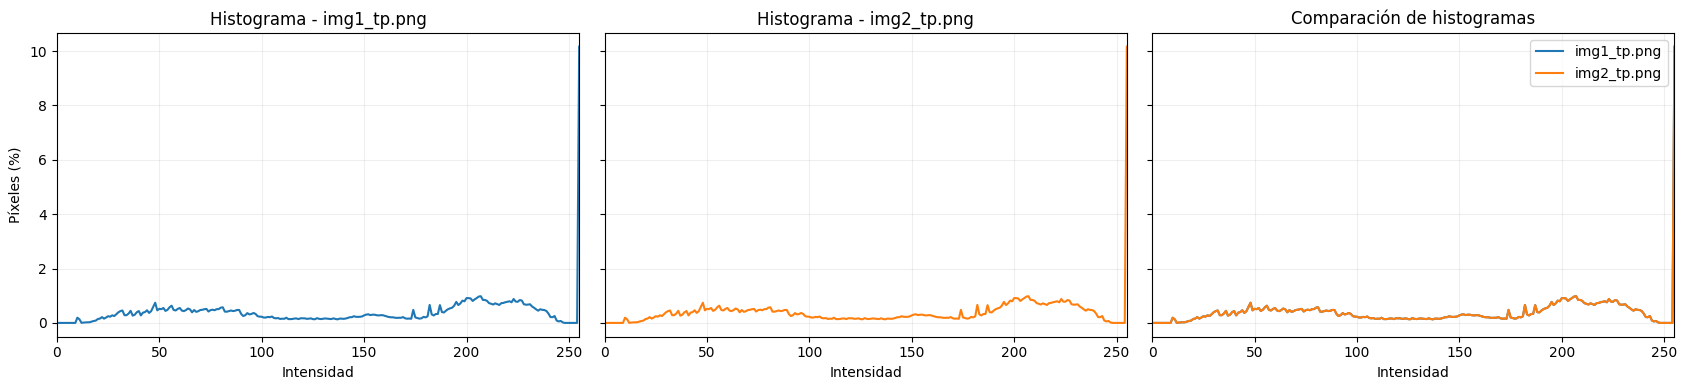

In [9]:

# Cálculo de histogramas con 256 bins
num_bins = 256
histogramas = {}

for nombre, imagen in imagenes_grises.items():
    hist, _ = np.histogram(imagen.ravel(), num_bins, [0, 256])

    # Frecuencia relativa de cada nivel de intensidad
    frecuencia = hist * 100 / imagen.size
    histogramas[nombre] = frecuencia


# Visualización individual y comparación
fig, axes = plt.subplots(1, 3, figsize=(17, 4),
                         sharex=True, sharey=True)

colores = ['tab:blue', 'tab:orange']

for i, (nombre, hist) in enumerate(histogramas.items()):
    axes[i].plot(hist, color=colores[i], linewidth=1.5)
    axes[i].set_title(f'Histograma - {nombre}')

    # Comparación de ambas distribuciones
    axes[2].plot(hist, color=colores[i],
                 label=nombre, linewidth=1.5)

axes[2].set_title('Comparación de histogramas')
axes[2].legend()

for ax in axes:
    ax.set_xlim(0, 255)
    ax.set_xlabel('Intensidad')
    ax.grid(alpha=0.2)

axes[0].set_ylabel('Píxeles (%)')

plt.tight_layout()
plt.show()



**Observaciones**

- Los histogramas de `img1_tp.png` y `img2_tp.png` coinciden exactamente en sus 256 bins. Aunque las imágenes muestran contenidos visuales distintos, ambas contienen la misma cantidad de píxeles para cada nivel de intensidad.

- Las distribuciones presentan concentraciones importantes entre las intensidades 40 y 90, y nuevamente entre 190 y 235. No se observa una distribución uniforme de los niveles de gris, incluso en la imagen que presenta un gradiente visualmente continuo.

- El pico más pronunciado corresponde a la intensidad 255, con 8400 píxeles en cada imagen, aproximadamente el 10.16 % del total. Esto explica que ambas gráficas alcancen su máximo en el extremo derecho.

- En la gráfica comparativa, las curvas se superponen completamente. No se trata de un error de visualización, sino de una coincidencia real entre sus distribuciones de intensidad.

- La elección de 256 bins permitió verificar esta igualdad sin agrupar niveles de gris. Sin embargo, los histogramas no reflejan la disposición espacial de los píxeles, por lo que no permiten distinguir el gradiente de la primera imagen de la flor presente en la segunda.

Este resultado evidencia que dos imágenes visualmente diferentes pueden compartir exactamente la misma distribución de intensidades.



### 2.3 Histogramas como características

A partir de los resultados obtenidos, se analiza la utilidad de los histogramas como características (*features*) para tareas de clasificación y detección de imágenes.

**Análisis**

- Los histogramas pueden aportar información sobre la distribución de intensidades, el brillo y el contraste de una imagen. En clasificación, podrían ser útiles cuando las categorías presentan diferencias en estas características.

- Sin embargo, `img1_tp.png` y `img2_tp.png` tienen histogramas idénticos pese a mostrar contenidos completamente diferentes. Un clasificador que utilizara únicamente estos 256 valores recibiría las mismas características para ambas imágenes y no podría distinguirlas.

- Para tareas de detección, la limitación es mayor. Un histograma global no conserva la posición de los píxeles ni la forma de los objetos, por lo que no permitiría localizar la flor dentro de `img2_tp.png`.

- Por tanto, los histogramas pueden utilizarse como características complementarias, pero no serían suficientes por sí solos cuando necesitamos reconocer estructuras o localizar objetos. En esos casos, es necesario incorporar información espacial.

Este ejemplo demuestra que una misma distribución de intensidades puede corresponder a imágenes visualmente distintas, lo que limita su capacidad de representación como característica única.


### Conclusiones de la Parte 2

- El análisis permitió comprobar que dos imágenes visualmente diferentes pueden presentar histogramas idénticos. Aunque sus contenidos son distintos, ambas comparten exactamente la misma distribución de intensidades.

- La elección de 256 bins permitió examinar todos los niveles de gris sin agrupar valores. Sin embargo, este nivel de detalle no permite recuperar la información espacial que el histograma no representa.

- Los histogramas pueden aportar características útiles para clasificación, pero en este caso no permitirían distinguir ambas imágenes. Para tareas de detección, tampoco serían suficientes para localizar objetos, por lo que resulta necesario complementarlos con información sobre su estructura y posición.

En conclusión, los histogramas describen adecuadamente la distribución de intensidades, pero su utilidad como características depende de la información que se necesite extraer de cada imagen.